Published values are separated from implementation assumptions. Polymer concentration in a.u. is converted to particle counts 1:1 as an assumption.

Reported initial conditions and parameters: 50×50 grid; 25 initial bacteria (or 2 in one BB170 scenario); maximum 80; 2×2 bacterial footprint; MM32 starts with 10,000 signals; BB170 starts with 0 and produces signals at 0.005 per bacterium; DB=0.0005, DP=0.01, DS=0.05; KBS=0.5, forward rate 0.001 and reverse rate 0.002; 60 bacterial signal-binding sites; 120 bacterial polymer-binding sites; 2 bacterial sites and 5 signal sites per polymer; crowding threshold Pc=10; Ksyn=0.05; nominal protein degradation magnitude 0.01; luminescence scale 2500; BSc=38 (MM32) or 15 (BB170); outputs every 100 a.u. from 0 to 30,000 a.u.; 10 runs. Not all of these are implemented mechanistically, as noted in the limitations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
OUT = Path('q3_results'); OUT.mkdir(exist_ok=True)
N=50; BMAX=80; DT=100.; TMAX=30000.
TIMES=np.arange(0,TMAX+DT,DT)
SEEDS=list(range(1000,1010))
D_B=0.0005; D_P=0.01; D_S=0.05
K_BS_ON=0.001; K_BS_OFF=0.002
K_SYN=0.05; K_DEGRAD=0.01
SCALE=2500.; PC=10
AFFINITIES=[0.1,0.5,1,5,10]
# ASSUMPTIONS: polymer forward rates, luminescence response, effective time scaling
K_PB_ON=0.001; K_PS_ON=0.001
MOLECULE_DT=1.0  # one approximate molecule diffusion step per 100 a.u. output interval
print('10 seeds:', SEEDS)

10 seeds: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009]


The bacteria occupy 2×2 cells on the lattice. Free signals and polymers diffuse; signals can bind/unbind bacterial receptors, and polymers can bind/unbind signals. Bacteria divide at sampled times. Important deviations: Polymer–bacterium binding and cluster bridging are not simulated as chemical bonds; kpb only affects a heuristic movement slowdown. The algorithm is a fixed-step stochastic approximation, not Gillespie's direct method. The absolute polymer binding rates, a.u.-to-particle conversion, signal transport correction and luminescence sigmoid are assumptions. These limitations affect scientific conclusions.

In [2]:
DIRS=np.array([[-1,0],[1,0],[0,-1],[0,1]])
def place_bacteria(rng, count):
    grid=np.zeros((N,N),dtype=np.int16); pos=[]
    for ident in range(1,count+1):
        for _ in range(10000):
            x,y=rng.integers(0,N-1,size=2)
            if not grid[x:x+2,y:y+2].any():
                grid[x:x+2,y:y+2]=ident; pos.append((int(x),int(y)));break
        else:raise RuntimeError('Could not place bacterium')
    return grid,pos

def diffuse_counts(a, rate, rng):
    # probability of a hop in one *approximate* molecular time step
    p=min(1.,4*rate*MOLECULE_DT)
    movers=rng.binomial(a,p)
    remaining=a-movers
    # multinomial splitting via successive conditional binomials
    left=movers.copy(); parts=[]
    for d in (4,3,2):
        z=rng.binomial(left,1/d); parts.append(z);left-=z
    parts.append(left)
    for (dx,dy),part in zip(DIRS,parts):
        moved=np.roll(part,(dx,dy),(0,1))
        if dx==1: moved[0,:]=0; remaining[N-1,:]+=part[N-1,:]
        if dx==-1: moved[N-1,:]=0; remaining[0,:]+=part[0,:]
        if dy==1: moved[:,0]=0; remaining[:,N-1]+=part[:,N-1]
        if dy==-1: moved[:,N-1]=0; remaining[:,0]+=part[:,0]
        remaining+=moved
    assert remaining.sum()==a.sum()
    return remaining

def local_count(a,x,y):return int(a[x:x+2,y:y+2].sum())

In [3]:
def simulate_spatial(strain='MM32', polymer=0, kpb=0., kps=0.,
                     seed=1000, initial_bacteria=25, doubling_time=15000):
    rng=np.random.default_rng(seed)
    bg,pos=place_bacteria(rng,initial_bacteria)
    polymers=rng.multinomial(int(polymer),np.full(N*N,1/(N*N))).reshape(N,N)
    signals=rng.multinomial(10000 if strain=='MM32' else 0,
                            np.full(N*N,1/(N*N))).reshape(N,N)
    # receptor-bound signals per bacterium; bound polymer-signal counts per grid cell
    bs=np.zeros(initial_bacteria,dtype=np.int32)
    expr=np.zeros(initial_bacteria,dtype=float)
    ps=np.zeros((N,N),dtype=np.int32)
    next_div=rng.triangular(doubling_time-10000,doubling_time,doubling_time+10000,
                            size=initial_bacteria).tolist()
    trace=[]; pop=[]
    for t in TIMES:
        # Record the state after the previous interval
        bsc=38 if strain=='MM32' else 15
        delta=np.clip(0.25*(expr-bsc),-50,50)
        light=SCALE/(1+np.exp(-delta))  # ASSUMED sigmoid; not the printed formula
        trace.append(float(light.sum()))
        pop.append(len(pos))
        if t==TIMES[-1]:break
        # Signal production for BB170: Poisson(0.005 * bacteria * dt)
        if strain=='BB170':
            for x,y in pos:
                made=int(rng.poisson(0.005*DT))
                if made:
                    add=rng.multinomial(made,[0.25]*4).reshape(2,2)
                    signals[x:x+2,y:y+2]+=add
        # Polymer-signal binding, local, with crowding threshold
        if kps>0:
            capacity=np.maximum(0,5*polymers-ps)
            capacity=np.where(polymers<PC,capacity,0)
            # ASSUMED tau-leap on-rate scaling
            want=rng.binomial(signals,1-np.exp(-K_PS_ON*capacity*MOLECULE_DT))
            bind=np.minimum(want,capacity)
            signals-=bind; ps+=bind
            off=rng.binomial(ps,1-np.exp(-(K_PS_ON/kps)*MOLECULE_DT))
            ps-=off; signals+=off
        # Bacteria-signal reversible binding
        for i,(x,y) in enumerate(pos):
            free=local_count(signals,x,y)
            available=max(0,60-int(bs[i]))
            if free and available:
                b=int(min(free,available,rng.binomial(free,1-np.exp(-K_BS_ON*available*MOLECULE_DT))))
                if b:
                    counts=signals[x:x+2,y:y+2].ravel()
                    chosen=rng.multivariate_hypergeometric(counts,b).reshape(2,2)
                    signals[x:x+2,y:y+2]-=chosen
                    bs[i]+=b
            off=int(rng.binomial(int(bs[i]),1-np.exp(-K_BS_OFF*MOLECULE_DT)))
            bs[i]-=off
            if off:
                signals[x:x+2,y:y+2]+=rng.multinomial(off,[.25]*4).reshape(2,2)
        # Update protein expression over DT, avoiding Euler overshoot
        sensed=bs.astype(float)
        up=sensed>expr
        expr[up]=sensed[up]+(expr[up]-sensed[up])*np.exp(-K_SYN*DT)
        expr[~up]*=np.exp(-K_DEGRAD*DT)
        # Stochastic diffusion of unbound molecules
        polymers=diffuse_counts(polymers,D_P,rng)
        signals=diffuse_counts(signals,D_S,rng)
        # Approximate polymer-induced slowing of bacterial movement
        # (does NOT implement exact connected-component cluster movement)
        for i,(x,y) in enumerate(list(pos)):
            local_poly=local_count(polymers,x,y)
            slow=1+kpb*local_poly/10
            if rng.random()>=1-np.exp(-4*D_B*DT/slow):continue
            dx,dy=DIRS[rng.integers(4)]; nx,ny=x+int(dx),y+int(dy)
            if not(0<=nx<=N-2 and 0<=ny<=N-2):continue
            ident=i+1;bg[x:x+2,y:y+2]=0
            if not bg[nx:nx+2,ny:ny+2].any():
                bg[nx:nx+2,ny:ny+2]=ident;pos[i]=(nx,ny)
            else:bg[x:x+2,y:y+2]=ident
        # Division (triangular intervals, 2x2 daughter, max 80)
        for i in range(len(pos)):
            if len(pos)>=BMAX:break
            if t+DT<next_div[i]:continue
            x,y=pos[i]
            candidates=[(x-2,y),(x+2,y),(x,y-2),(x,y+2)]
            rng.shuffle(candidates)
            placed=False
            for nx,ny in candidates:
                if 0<=nx<=N-2 and 0<=ny<=N-2 and not bg[nx:nx+2,ny:ny+2].any():
                    bg[nx:nx+2,ny:ny+2]=len(pos)+1
                    pos.append((nx,ny));bs=np.append(bs,0);expr=np.append(expr,0.)
                    next_div.append(t+DT+rng.triangular(doubling_time-10000,doubling_time,doubling_time+10000))
                    placed=True;break
            next_div[i]=(t+DT+rng.triangular(doubling_time-10000,doubling_time,doubling_time+10000)) if placed else t+2*DT
    return np.array(trace),np.array(pop)


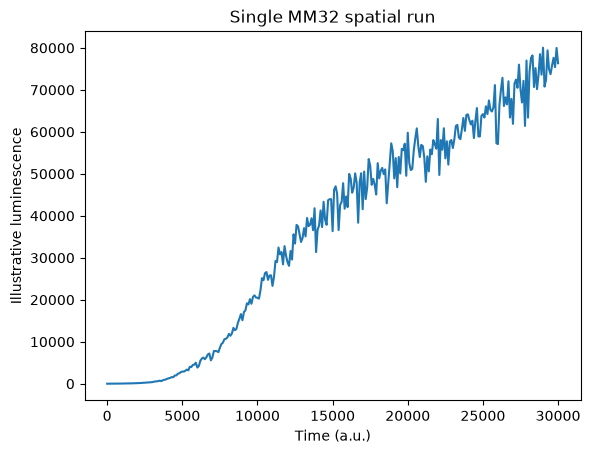

Initial / final bacteria: 25 77


In [4]:
test,pop=simulate_spatial(seed=1000,polymer=3000,kpb=5,kps=0)
assert len(test)==len(TIMES) and np.all(np.isfinite(test))
assert np.max(pop)<=80
plt.plot(TIMES,test);plt.xlabel('Time (a.u.)');plt.ylabel('Illustrative luminescence');plt.title('Single MM32 spatial run');plt.show()
print('Initial / final bacteria:',pop[0],pop[-1])

In [5]:
# Basic reproducibility and invariant checks before the full runs
check_light, check_pop = simulate_spatial(seed=1000, polymer=3000, kpb=5, kps=0)
assert len(check_light) == 301
assert np.isfinite(check_light).all()
assert check_pop.min() >= 25 and check_pop.max() <= 80
assert len(SEEDS) == 10 and len(set(SEEDS)) == 10
print('Checks passed: 301 outputs, finite luminescence, valid population, unique seeds.')

Checks passed: 301 outputs, finite luminescence, valid population, unique seeds.


In [6]:
def replicates(**kwargs):
    return np.stack([simulate_spatial(seed=s,**kwargs)[0] for s in SEEDS])
def plot_mean(runs,label):
    mean=runs.mean(axis=0);sd=runs.std(axis=0,ddof=1)
    plt.plot(TIMES,mean,label=label)
    plt.fill_between(TIMES,mean-sd,mean+sd,alpha=.15)
def save_runs(name,runs):
    df=pd.DataFrame({'time_au':TIMES,'mean':runs.mean(axis=0),
                     'sd':runs.std(axis=0,ddof=1)})
    for i,seed in enumerate(SEEDS):df[f'seed_{seed}']=runs[i]
    df.to_csv(OUT/f'{name}.csv',index=False)
pd.DataFrame({'run':range(1,11),'seed':SEEDS}).to_csv(OUT/'seeds.csv',index=False)

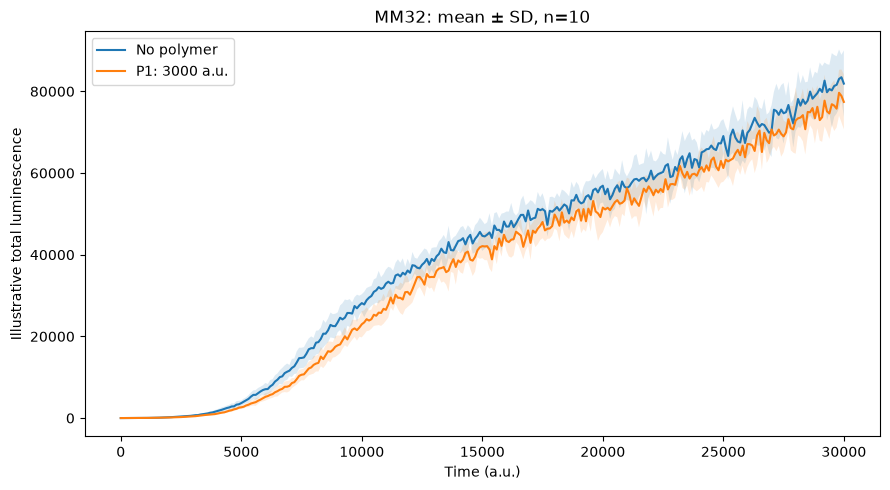

In [7]:
control=replicates(strain='MM32',polymer=0,kpb=0,kps=0)
p1=replicates(strain='MM32',polymer=3000,kpb=5,kps=0)
save_runs('MM32_control',control);save_runs('MM32_P1_3000',p1)
plt.figure(figsize=(9,5));plot_mean(control,'No polymer');plot_mean(p1,'P1: 3000 a.u.')
plt.xlabel('Time (a.u.)');plt.ylabel('Illustrative total luminescence');plt.title('MM32: mean ± SD, n=10')
plt.legend();plt.tight_layout();plt.savefig(OUT/'MM32_control_vs_P1.png',dpi=150);plt.show()

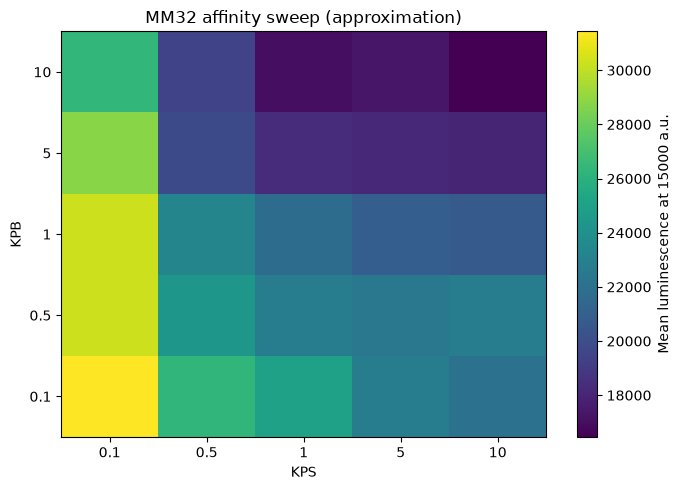

In [8]:
records=[]
for kpb in AFFINITIES:
    for kps in AFFINITIES:
        runs=replicates(strain='MM32',polymer=3000,kpb=kpb,kps=kps)
        save_runs(f'MM32_KPB_{kpb}_KPS_{kps}',runs)
        records.append({'KPB':kpb,'KPS':kps,'mean_at_15000':runs[:,150].mean(),
                        'mean_at_30000':runs[:,-1].mean()})
affinity_df=pd.DataFrame(records);affinity_df.to_csv(OUT/'affinity_summary.csv',index=False)
heat=affinity_df.pivot(index='KPB',columns='KPS',values='mean_at_15000')
plt.figure(figsize=(7,5));plt.imshow(heat,origin='lower',aspect='auto')
plt.xticks(range(5),AFFINITIES);plt.yticks(range(5),AFFINITIES)
plt.xlabel('KPS');plt.ylabel('KPB');plt.colorbar(label='Mean luminescence at 15000 a.u.')
plt.title('MM32 affinity sweep (approximation)');plt.tight_layout()
plt.savefig(OUT/'affinity_heatmap.png',dpi=150);plt.show()

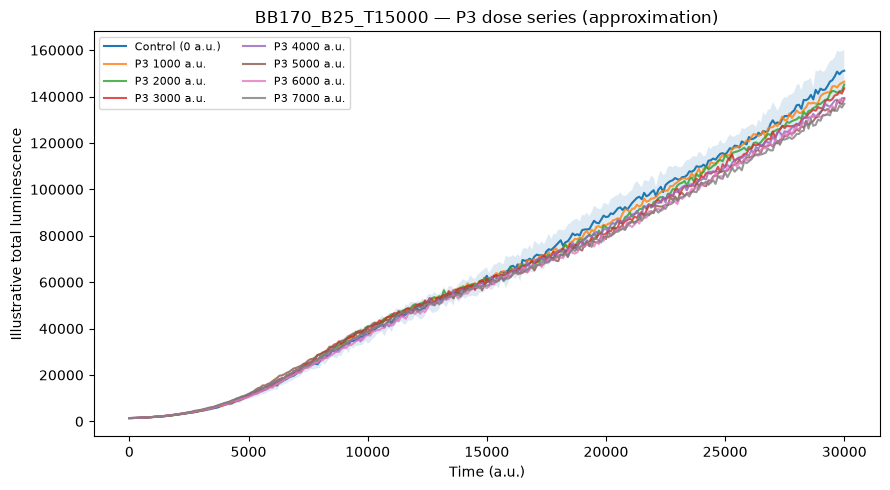

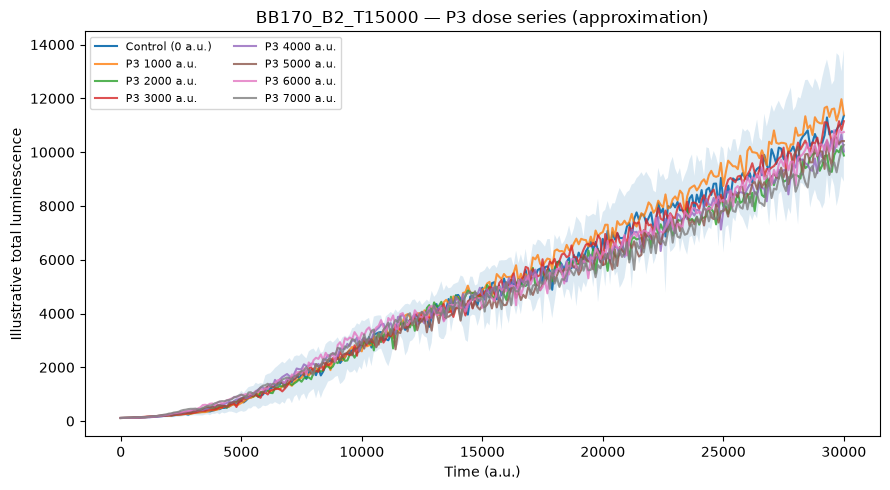

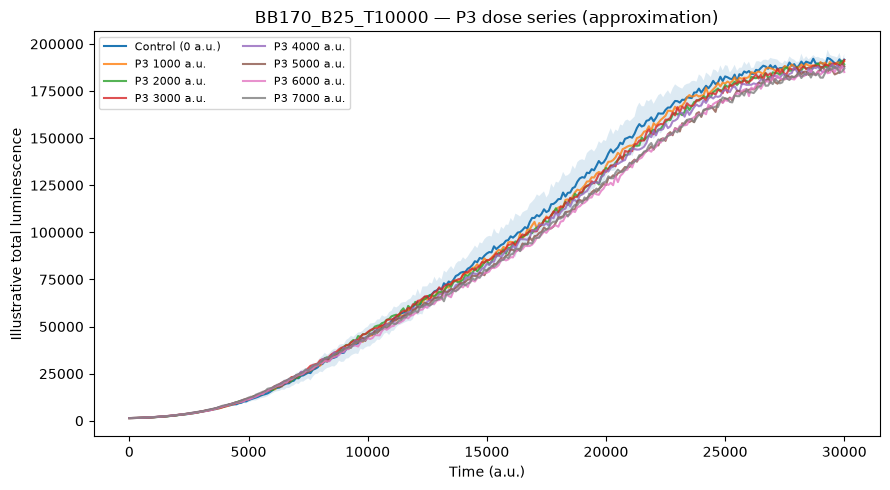

In [9]:
# BB170 dose series for the three published scenario settings
scenarios = [
    ('BB170_B25_T15000', 25, 15000),
    ('BB170_B2_T15000', 2, 15000),
    ('BB170_B25_T10000', 25, 10000)
]
DOSES = list(range(0, 7001, 1000))

for name, b0, division in scenarios:
    plt.figure(figsize=(9, 5))
    control = replicates(strain='BB170', polymer=0, kpb=0, kps=0,
                         initial_bacteria=b0, doubling_time=division)
    save_runs(name + '_control', control)
    control_mean = control.mean(axis=0)
    plot_mean(control, 'Control (0 a.u.)')

    for dose in DOSES[1:]:
        runs = replicates(strain='BB170', polymer=dose, kpb=5, kps=10,
                          initial_bacteria=b0, doubling_time=division)
        save_runs(f'{name}_P3_{dose}', runs)
        plt.plot(TIMES, runs.mean(axis=0), label=f'P3 {dose} a.u.', alpha=0.8)

        # Ratio of mean luminescence to mean control luminescence
        # (defined where the control is nonzero)
        fold = np.divide(runs.mean(axis=0), control_mean,
                         out=np.full_like(control_mean, np.nan),
                         where=control_mean > 1e-12)
        pd.DataFrame({'time_au': TIMES, 'fold_change': fold}).to_csv(
            OUT / f'{name}_P3_{dose}_fold_change.csv', index=False)

    plt.title(name + ' — P3 dose series (approximation)')
    plt.xlabel('Time (a.u.)')
    plt.ylabel('Illustrative total luminescence')
    plt.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(OUT / (name + '_dose_series.png'), dpi=150)
    plt.show()
